# **PREDICTING A STROKE**



Strokes are amongst the leading causes of death and disability throughout the world, accounting for about 6 million deaths per year globally. Not to mention, of course, the thousands who survive a stroke and are left with life-long disabilities that impact their quality of life.
Studies have found many factors that seem to increase the risk of a stroke, like heart disease, hypertension, diabetes, smoking, obesity and lifestyle.
The aim of this model is to aid healthcare workers by predicting the likelihood of someone suffering a stroke, thus allowing for timely interventions or, even, prevention.
Multiple algorithms will be applied and then compared so that we may find the most accurate model.

## LIBRARIES

First and foremost, let us import all the necessary libraries.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno
import kagglehub
import os
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, learning_curve, StratifiedKFold, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import classification_report, roc_auc_score, precision_score, recall_score, f1_score, confusion_matrix, accuracy_score
from imblearn.over_sampling import SMOTE
import plotly.express as px
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier
from scipy.stats import uniform
from IPython.display import display, Markdown

In [2]:
path = kagglehub.dataset_download("aouatifcherdid/healthcare-dataset-stroke-data") # download the dataset from Kaggle

df = pd.read_csv(os.path.join(path, "healthcare-dataset-stroke-data.csv")) # we load the dataset

100%|██████████| 67.4k/67.4k [00:00<00:00, 7.78MB/s]

Extracting files...


## EDA
---



We can now begin our investigation of the dataset. This way we can gain information on our dataset and use it to help us build our model. We can get insight on trends, patterns, outliers and such so that we may better understand the relation between certain factors and the risk of suffering a stroke. We also can find out if there are any missing values within our dataset, which is a crucial information that will be needed later for data preprocessing. We also check our dataset for imbalances, another vital piece of information necessary for our model to work properly, and we visualize all the information via plots and charts.

The dataset is available on kaggle.com.

The dataset contains 5110 rows — representing the individuals — and 12 columns — representing the features. The features are:

- ID: assigns an ID number to each individual (it does not provide any information that is useful for our prediction, therefore this column will be dropped later on in the project);

- Gender: gender of the individual (Male or Female);

- Age: age of the individual (numerical value);

- Hypertension: whether the individual suffers from hypertension or not (0 or 1);

- Ever_married: whether the individual is, or has been, married (Yes or No);

- Work_type: the type of job the individual has (private, self-employed, government job);

- Residence_type: the type of residence the individual lives in (urban or rural);

- Avg_glucose_level: the average glucose level of the individual (numerical value);

- BMI: the individual's BMI (numerical value);

- Smoking_status: whether the individual is a current smoker, former smoker or never smoked;

- Stroke: whether the individual suffered a stroke ot not (0 or 1);

This machine learning model is a binary classification that aims to predict the likelihood of someone suffering a stroke based on the features provided.

In [3]:
df.info()  # we check the features of the dataset

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


In [4]:
categorical_columns = df.columns[df.dtypes == 'object']  # here we split the features into numerical and categorical, this is going to be useful later on
numerical_columns = df.columns[df.dtypes != 'object']  # when we tranform the dataset in order to conform all feautures to one type

print(f"Categorical columns: {categorical_columns}")
print(f"Numerical columns: {numerical_columns}")

Categorical columns: Index(['gender', 'ever_married', 'work_type', 'Residence_type',
       'smoking_status'],
      dtype='object')
Numerical columns: Index(['id', 'age', 'hypertension', 'heart_disease', 'avg_glucose_level',
       'bmi', 'stroke'],
      dtype='object')


In [5]:
df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [6]:
df.describe()  # we check the statistics of the dataset

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


In [7]:
for column in df.columns:  # we check for unique values in the set
    unique_values = df[column].unique()
    print(f"Unique values in {column}: {unique_values}")

Unique values in id: [ 9046 51676 31112 ... 19723 37544 44679]
Unique values in gender: ['Male' 'Female' 'Other']
Unique values in age: [6.70e+01 6.10e+01 8.00e+01 4.90e+01 7.90e+01 8.10e+01 7.40e+01 6.90e+01
 5.90e+01 7.80e+01 5.40e+01 5.00e+01 6.40e+01 7.50e+01 6.00e+01 5.70e+01
 7.10e+01 5.20e+01 8.20e+01 6.50e+01 5.80e+01 4.20e+01 4.80e+01 7.20e+01
 6.30e+01 7.60e+01 3.90e+01 7.70e+01 7.30e+01 5.60e+01 4.50e+01 7.00e+01
 6.60e+01 5.10e+01 4.30e+01 6.80e+01 4.70e+01 5.30e+01 3.80e+01 5.50e+01
 1.32e+00 4.60e+01 3.20e+01 1.40e+01 3.00e+00 8.00e+00 3.70e+01 4.00e+01
 3.50e+01 2.00e+01 4.40e+01 2.50e+01 2.70e+01 2.30e+01 1.70e+01 1.30e+01
 4.00e+00 1.60e+01 2.20e+01 3.00e+01 2.90e+01 1.10e+01 2.10e+01 1.80e+01
 3.30e+01 2.40e+01 3.40e+01 3.60e+01 6.40e-01 4.10e+01 8.80e-01 5.00e+00
 2.60e+01 3.10e+01 7.00e+00 1.20e+01 6.20e+01 2.00e+00 9.00e+00 1.50e+01
 2.80e+01 1.00e+01 1.80e+00 3.20e-01 1.08e+00 1.90e+01 6.00e+00 1.16e+00
 1.00e+00 1.40e+00 1.72e+00 2.40e-01 1.64e+00 1.56e+00 7.20e-

In [8]:
df.nunique()

,0
id,5110
gender,3
age,104
hypertension,2
heart_disease,2
ever_married,2
work_type,5
Residence_type,2
avg_glucose_level,3979
bmi,418


Upon inspecting the dataset, it's clearly visible that some values are missing despite the cells being filled. Therefore, we substitute those with np.nan and then check for missing values.

In [9]:
df.replace(["Unknown", "N/A", "Other", "Never_worked"], np.nan, inplace=True)

In [10]:
df.isnull().sum()  # we check for missing values

,0
id,0
gender,1
age,0
hypertension,0
heart_disease,0
ever_married,0
work_type,22
Residence_type,0
avg_glucose_level,0
bmi,201


<Axes: >

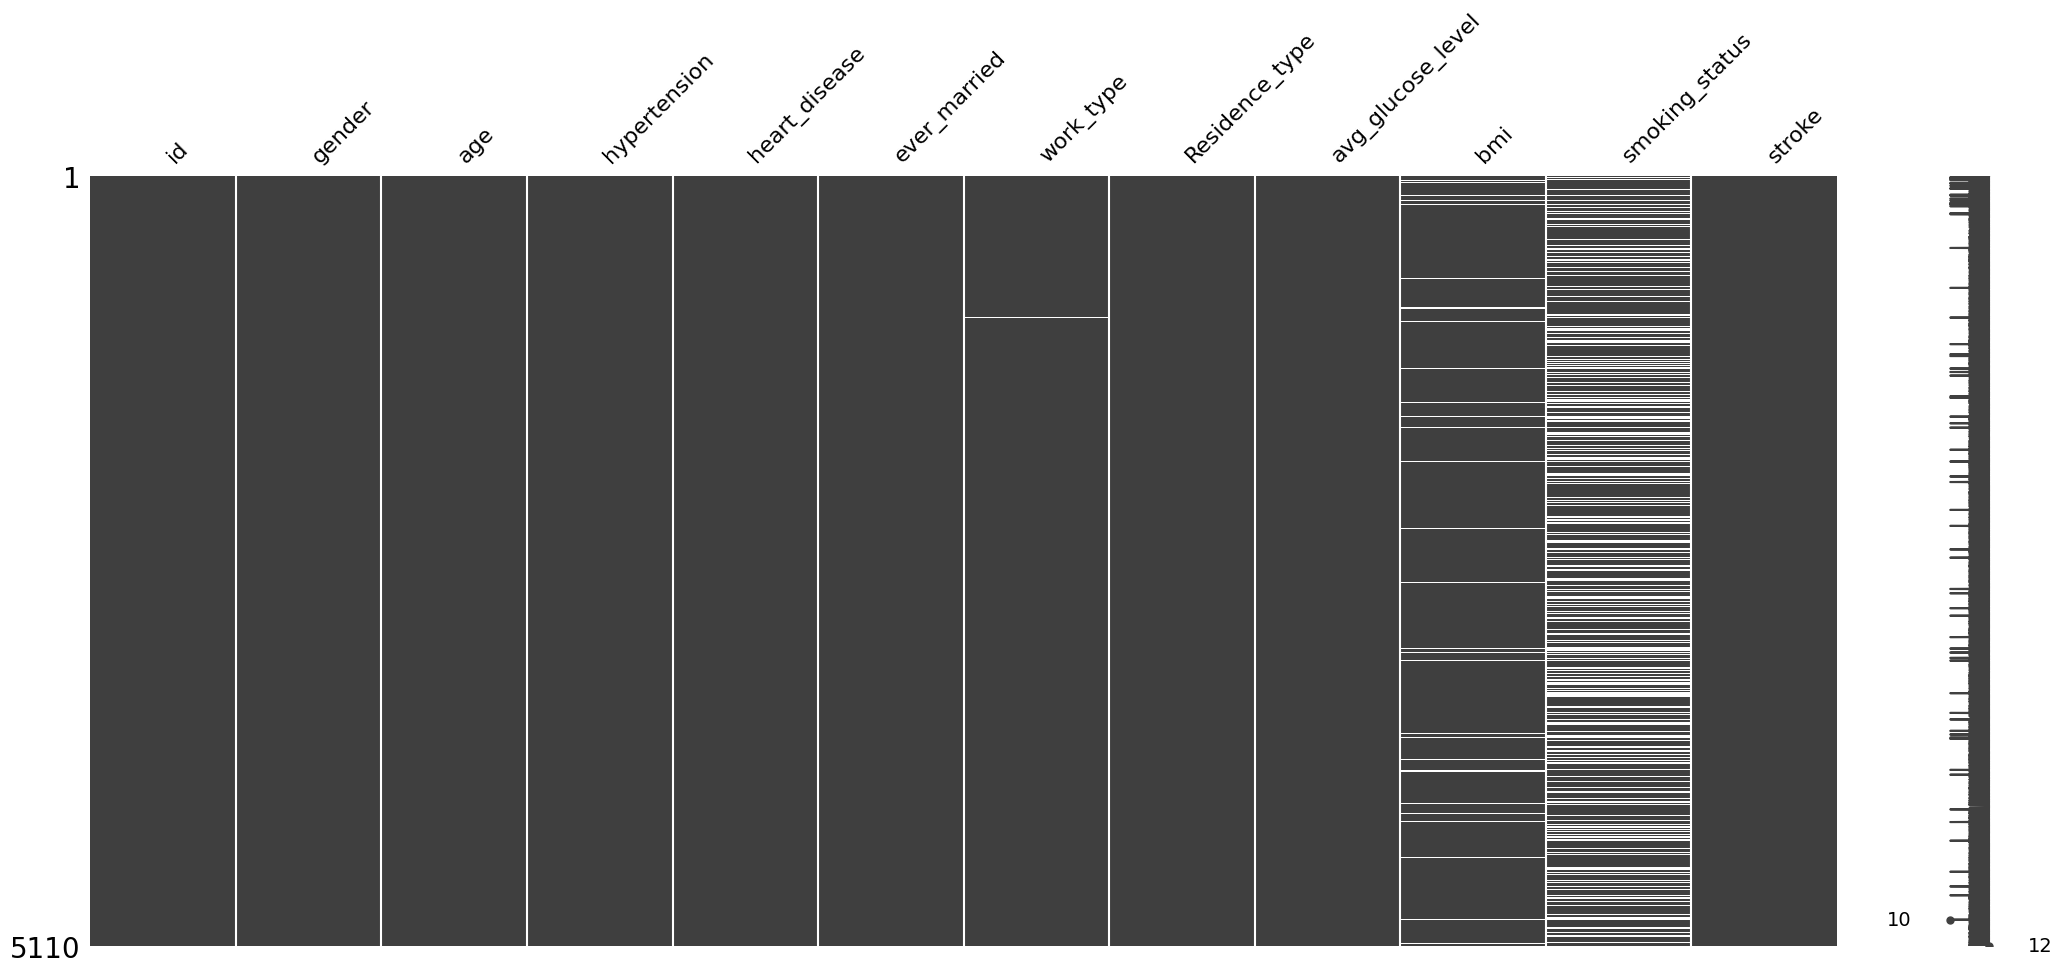

In [11]:
msno.matrix(df)  # we plot the missing values in order to help us visualize their distribution

We see that there are many missing values in "smoking_status", ordinarily, when such a situation occurs, such column would be dropped from the data, but seeing as many studies have proven a direct correlation between stroke risk and smoking, we will leave it and instead deal with it differently in the data preprocessing section.

We can now begin visualizing our data with the help of charts and plots.

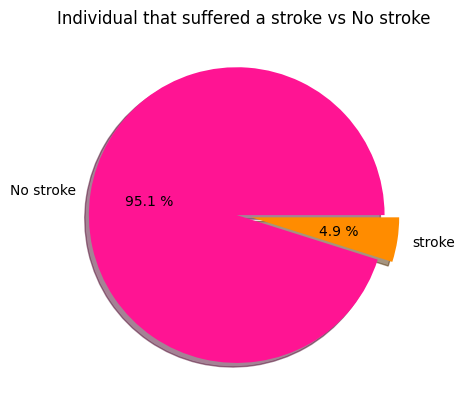

In [12]:
labels=["No stroke","stroke"]

stroke_or_not = df["stroke"].value_counts().tolist()
values = [stroke_or_not[0], stroke_or_not[1]]
explode=[.05,.05]
colors = ["deeppink", "darkorange"]

plt.title("Individual that suffered a stroke vs No stroke")
plt.pie(values, labels=labels, colors=colors, autopct='%.1f %%', explode=explode, shadow=True)
plt.show()


Clearly, the dataset is imbalanced, with only 4.9% of individuals having suffered a stroke. This is common with datasets related to the medical field, however, it needs to be addressed in order to having the model adopting a bias towards the predominant class (which, in this case, is people not having a stroke). It will be addressed sometime later in the project (by using Synthetic Minority Over-Sampling Technique).

<Axes: xlabel='age', ylabel='Count'>

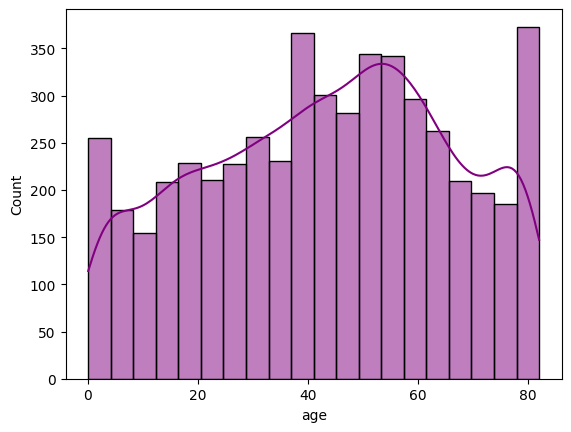

In [13]:
sns.histplot(data=df, x="age", kde=True, color="purple")  # we visualize the age of all individuals in the dataset

<Axes: xlabel='avg_glucose_level', ylabel='Count'>

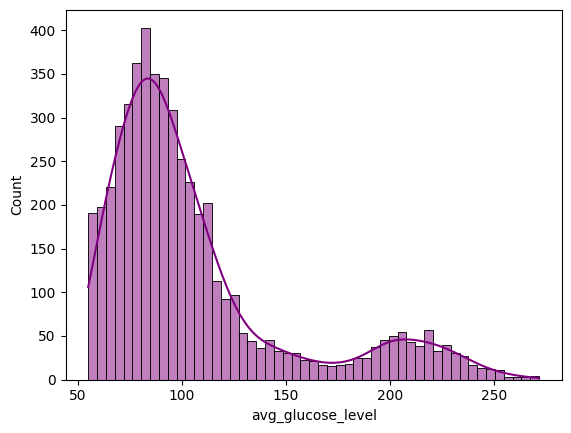

In [14]:
sns.histplot(data=df, x="avg_glucose_level", kde=True, color="purple")  # we visualize the average glucose level of all individuals in the dataset

The glucose level is included as it is an indicator of diabetes or insulin-resistance, which, according to studies, increases the risk of stroke.

<Axes: xlabel='bmi', ylabel='Count'>

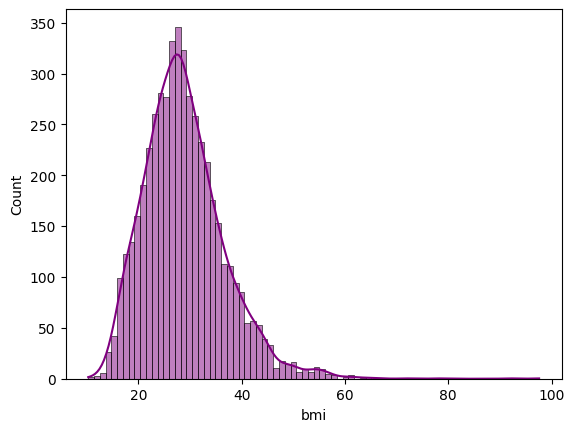

In [15]:
sns.histplot(data=df, x="bmi", kde=True, color="purple")  # we visualize the bmi of all individuals in the dataset

The BMI is an indicator of obesity, which studies have shown has a clear correlation to strokes.

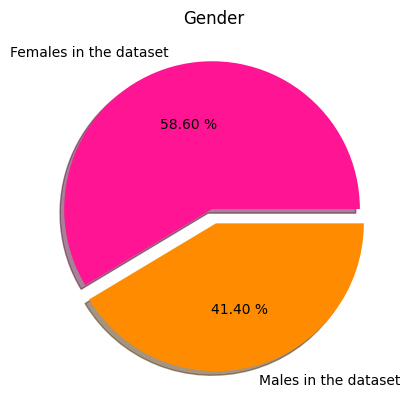

In [16]:
females = (df.loc[df["gender"]== "Female"]).shape[0]  # we visualize the amount of females and males within the dataset
males = (df.loc[df["gender"]== "Male"]).shape[0]

data = [females, males]
labels = ["Females in the dataset", "Males in the dataset"]
explode=[.05,.05]
colors = ["deeppink", "darkorange"]

plt.title("Gender")
plt.pie(data, labels=labels, colors=colors, autopct='%.2f %%', explode=explode, shadow=True)
plt.show()


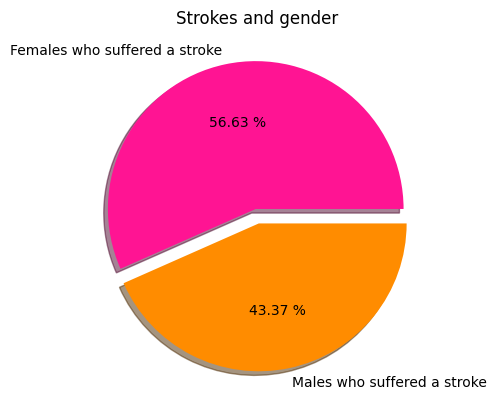

In [17]:
female_strokes = ((df.loc[df["gender"]== "Female"])["stroke"] == 1).sum()  # now we visualize strokes based off of gender
male_strokes = ((df.loc[df["gender"]== "Male"])["stroke"] == 1).sum()

data = [female_strokes, male_strokes]
labels = ["Females who suffered a stroke", "Males who suffered a stroke"]
explode=[.05,.05]
colors = ["deeppink", "darkorange"]

plt.title("Strokes and gender")
plt.pie(data, labels=labels, colors=colors, autopct='%.2f %%', explode=explode, shadow=True)
plt.show()


In [18]:
males = df[df["gender"] == "Male"].shape[0]
females =  df[df["gender"] == "Female"].shape[0]

total = males + females

male_percentage = (males/total)*100
female_percentages = (females/total)*100

print(f"The percentage of males in the dataset is: {male_percentage:.2f}%")
print(f"There are "+str(males)+" males in the dataset")
print(f"The percentage of females in the dataset is : {female_percentages:.2f}%")
print(f"There are "+str(females)+" females in the dataset")

difference_percentage = ((males - females)/females) * 100
print(f"The males are {difference_percentage:.2f}% more than females in the dataset.")

The percentage of males in the dataset is: 41.40%
There are 2115 males in the dataset
The percentage of females in the dataset is : 58.60%
There are 2994 females in the dataset
The males are -29.36% more than females in the dataset.


If looking at the "Strokes and gender" chart on its own, one might be tempted to say that females are more likely to suffer a stroke than males. However, upon a more thorough investigation, it becomes evident that is not the case — or, at least, is not indicated by the dataset. Seeing as the density of males within the dataset is lower than that of females, it makes sense that there would be more instances of females suffering strokes than males.

In [19]:
fig = px.histogram(data_frame=df, x="age", color= "stroke", color_discrete_sequence=["#b100cd", "#ff7600"])
fig.show()

/tmp/ipykernel_2957/1650212766.py:10: RuntimeWarning:

invalid value encountered in scalar divide



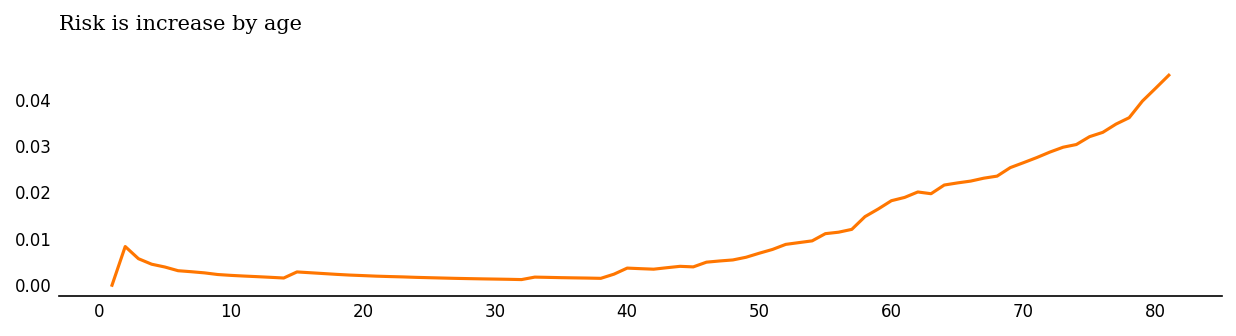

In [20]:
fig = plt.figure(figsize=(10, 5), dpi=150)
gs = fig.add_gridspec(2, 1)
gs.update(wspace=0.11, hspace=0.5)
ax0 = fig.add_subplot(gs[0, 0])

df["age"] = df["age"].astype(int)

rate = []
for i in range(df["age"].min(), df["age"].max()):
    rate.append(df[df["age"] < i]["stroke"].sum() / len(df[df["age"] < i]["stroke"]))

sns.lineplot(data=rate,color="#ff7600",ax=ax0)

for s in ["top","right","left"]:
    ax0.spines[s].set_visible(False)

ax0.tick_params(axis="both", which="major", labelsize=8)
ax0.tick_params(axis=u"both", which=u"both",length=0)

ax0.text(-3,0.055,"Risk is increase by age", font="Serif")

plt.show()

As shown above, in our dataset older people are more likely to suffer a stroke. This seems to agree with the research conducted on the topic. It should also be noted, however, that there is a higher incidence in the dataset of people who are 40 or older.

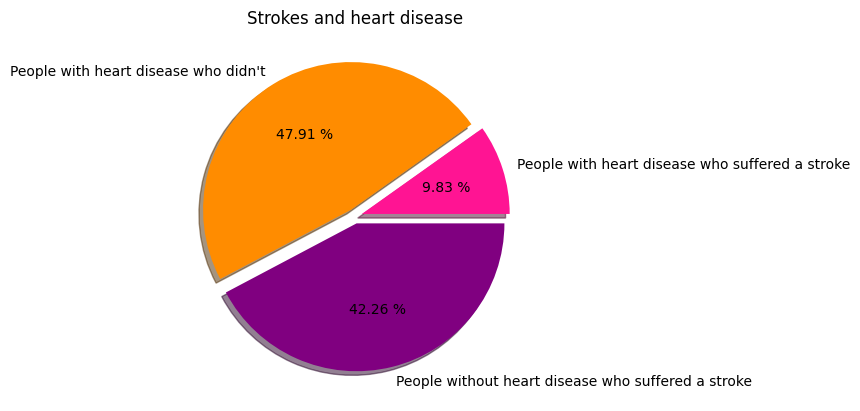

In [21]:
heart_disease_and_stroke = ((df.loc[df["heart_disease"]== 1])["stroke"] == 1).sum()
heart_disease_and_no_stroke = ((df.loc[df["heart_disease"]== 1])["stroke"] == 0).sum()
no_heart_disease_and_stroke = ((df.loc[df["heart_disease"]== 0])["stroke"] == 1).sum()

data = [heart_disease_and_stroke, heart_disease_and_no_stroke, no_heart_disease_and_stroke]
labels = ["People with heart disease who suffered a stroke", "People with heart disease who didn't", "People without heart disease who suffered a stroke"]
explode=[.05, .05, .05]
colors = ["deeppink", "darkorange", "purple"]

plt.title("Strokes and heart disease")
plt.pie(data, labels=labels, colors=colors, autopct='%.2f %%', explode=explode, shadow=True)
plt.show()

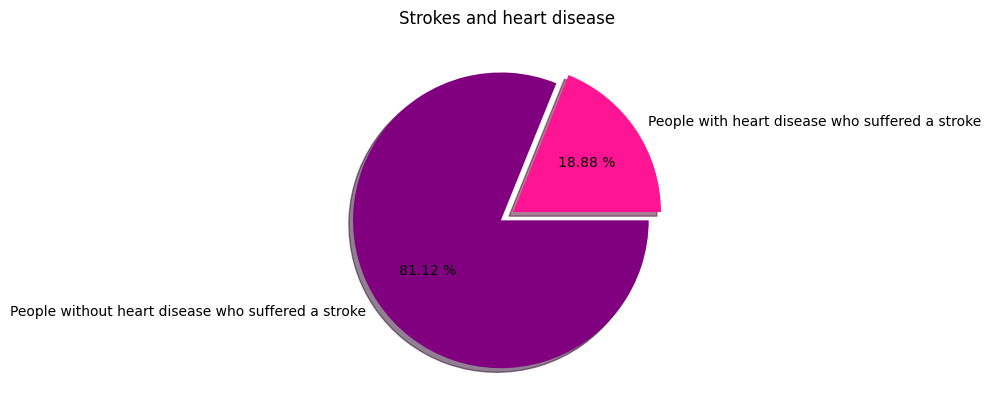

In [22]:
heart_disease_and_stroke = ((df.loc[df["heart_disease"]== 1])["stroke"] == 1).sum()
no_heart_disease_and_stroke = ((df.loc[df["heart_disease"]== 0])["stroke"] == 1).sum()

data = [heart_disease_and_stroke, no_heart_disease_and_stroke]
labels = ["People with heart disease who suffered a stroke", "People without heart disease who suffered a stroke"]
explode=[.05, .05]
colors = ["deeppink", "purple"]

plt.title("Strokes and heart disease")
plt.pie(data, labels=labels, colors=colors, autopct='%.2f %%', explode=explode, shadow=True)
plt.show()

According to statistics, people with an underlying heart condition are more likely to suffer a stroke than those who have no heart issues, however, this claim does seem to be reflected strongly within our dataset.

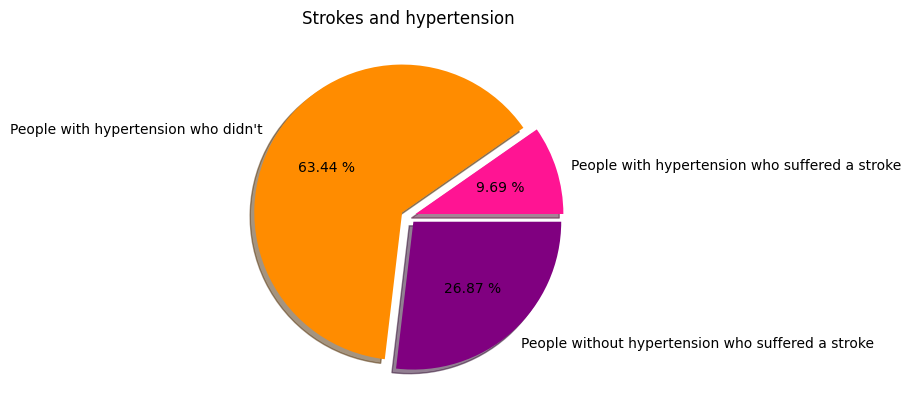

In [23]:
hypertension_and_stroke = ((df.loc[df["hypertension"]== 1])["stroke"] == 1).sum()
hypertension_and_no_stroke = ((df.loc[df["hypertension"]== 1])["stroke"] == 0).sum()
no_hypertension_and_stroke = ((df.loc[df["hypertension"]== 0])["stroke"] == 1).sum()

data = [hypertension_and_stroke, hypertension_and_no_stroke, no_hypertension_and_stroke]
labels = ["People with hypertension who suffered a stroke", "People with hypertension who didn't", "People without hypertension who suffered a stroke"]
explode=[.05,.05, .05]
colors = ["deeppink", "darkorange", "purple"]

plt.title("Strokes and hypertension")
plt.pie(data, labels=labels, colors=colors, autopct='%.2f %%', explode=explode, shadow=True)
plt.show()

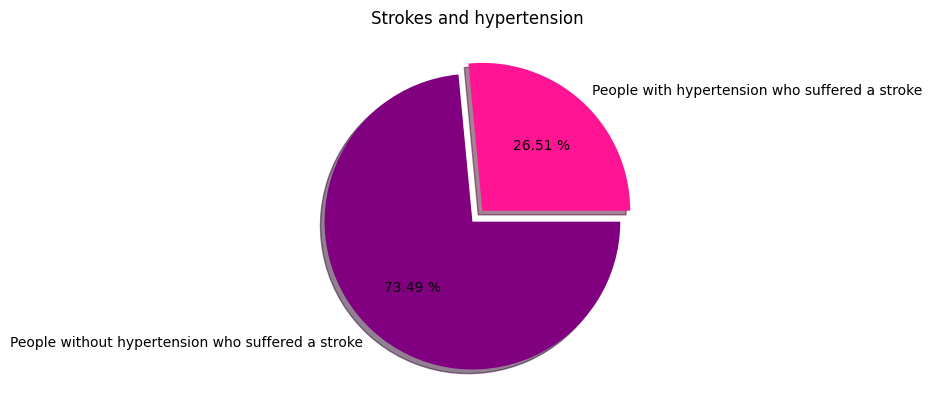

In [24]:
hypertension_and_stroke = ((df.loc[df["hypertension"]== 1])["stroke"] == 1).sum()
no_hypertension_and_stroke = ((df.loc[df["hypertension"]== 0])["stroke"] == 1).sum()

data = [hypertension_and_stroke, no_hypertension_and_stroke]
labels = ["People with hypertension who suffered a stroke", "People without hypertension who suffered a stroke"]
explode=[.05,.05]
colors = ["deeppink", "purple"]

plt.title("Strokes and hypertension")
plt.pie(data, labels=labels, colors=colors, autopct='%.2f %%', explode=explode, shadow=True)
plt.show()

Once more, despite the statistics available from multiple studies, our dataset does not seem to indicate a high correlation between hypertension and strokes.

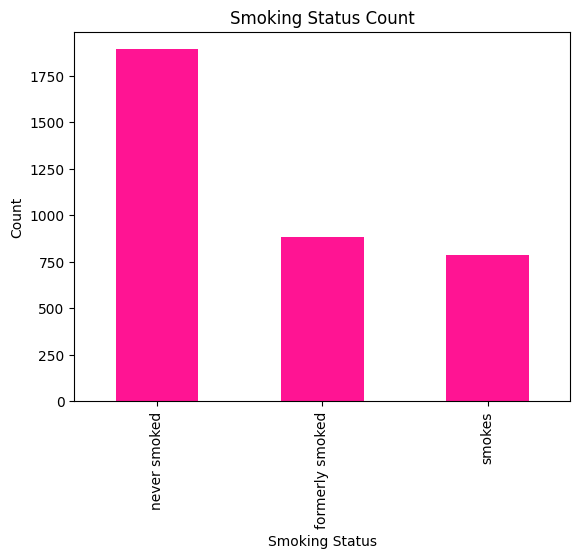

In [25]:
df["smoking_status"].value_counts().plot(kind="bar", color="deeppink")  # we visualize the amount of smokers, non-smokers and former smokers in the dataset
plt.title("Smoking Status Count")
plt.xlabel("Smoking Status")
plt.ylabel("Count")
plt.show()

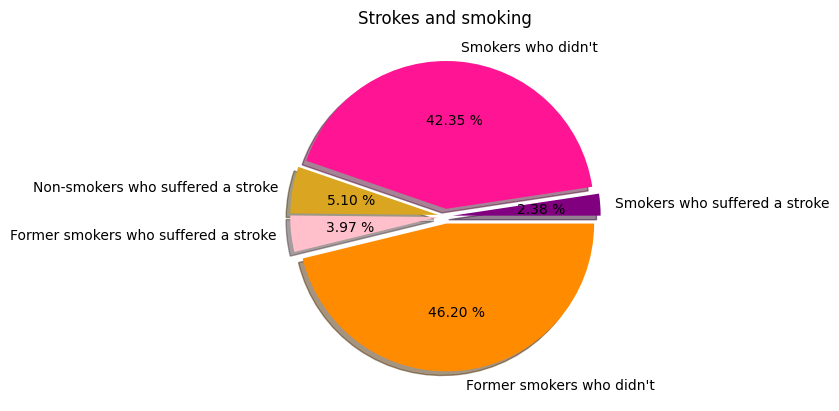

In [26]:
smoking_and_stroke = ((df.loc[df["smoking_status"]== "smokes"])["stroke"] == 1).sum()
smoking_and_no_stroke = ((df.loc[df["smoking_status"]== "smokes"])["stroke"] == 0).sum()
no_smoking_and_stroke = ((df.loc[df["smoking_status"]== "never smoked"])["stroke"] == 1).sum()
formerly_smoking_and_stroke = ((df.loc[df["smoking_status"]== "formerly smoked"])["stroke"] == 1).sum()
formerly_smoking_and_no_stroke = ((df.loc[df["smoking_status"]== "formerly smoked"])["stroke"] == 0).sum()

data = [smoking_and_stroke, smoking_and_no_stroke, no_smoking_and_stroke, formerly_smoking_and_stroke, formerly_smoking_and_no_stroke]
labels = ["Smokers who suffered a stroke", "Smokers who didn't", "Non-smokers who suffered a stroke", "Former smokers who suffered a stroke", "Former smokers who didn't" ]
explode=[.05,.05, .05, .05, .05]
colors = ["purple", "deeppink", "goldenrod", "pink", "darkorange"]

plt.title("Strokes and smoking")
plt.pie(data, labels=labels, colors=colors, autopct='%.2f %%', explode=explode, shadow=True)
plt.show()

Once more, no clear link between smoking and strokes within the dataset.

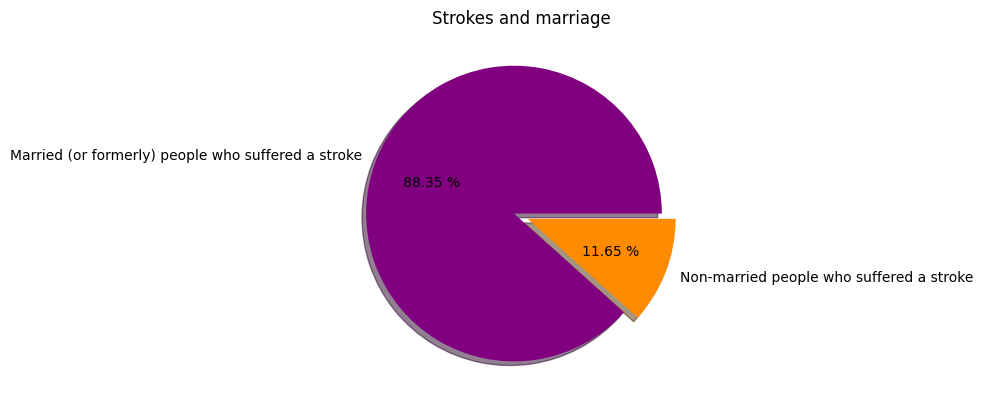

In [27]:
married_and_stroke = ((df.loc[df["ever_married"]== "Yes"])["stroke"] == 1).sum()
not_married_and_stroke = ((df.loc[df["ever_married"]== "No"])["stroke"] == 1).sum()

data = [married_and_stroke, not_married_and_stroke]
labels = ["Married (or formerly) people who suffered a stroke", "Non-married people who suffered a stroke"]
explode=[.05,.05]
colors = ["purple", "darkorange"]

plt.title("Strokes and marriage")
plt.pie(data, labels=labels, colors=colors, autopct='%.2f %%', explode=explode, shadow=True)
plt.show()

While it may not be intuitive, certain studies have shown a correlation between health issues and social factors. In this case, we only take marriage as a social factor, supposed to indicate companionship. It is obviously a very loose way to indicate how socially active an individual might be, therefore it should be taken with a grain of salt.

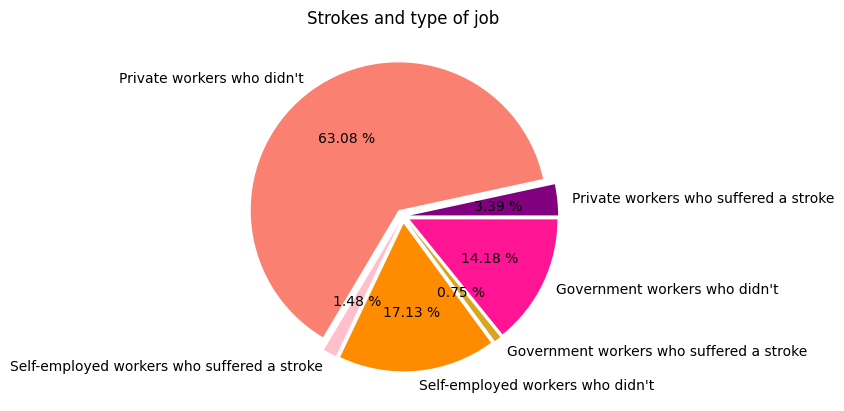

In [28]:
private_work_and_stroke = ((df.loc[df["work_type"]== "Private"])["stroke"] == 1).sum()
private_work_and_no_stroke = ((df.loc[df["work_type"]== "Private"])["stroke"] == 0).sum()
self_employed_and_stroke = ((df.loc[df["work_type"]== "Self-employed"])["stroke"] == 1).sum()
self_employed_and_no_stroke = ((df.loc[df["work_type"]== "Self-employed"])["stroke"] == 0).sum()
govt_work_and_stroke = ((df.loc[df["work_type"]== "Govt_job"])["stroke"] == 1).sum()
govt_work_and_no_stroke = ((df.loc[df["work_type"]== "Govt_job"])["stroke"] == 0).sum()

data = [private_work_and_stroke, private_work_and_no_stroke, self_employed_and_stroke, self_employed_and_no_stroke, govt_work_and_stroke, govt_work_and_no_stroke]
labels = ["Private workers who suffered a stroke", "Private workers who didn't", "Self-employed workers who suffered a stroke", "Self-employed workers who didn't", "Government workers who suffered a stroke", "Government workers who didn't"]
explode=[.05, .05, .05, .05, .05, .05]
colors = ["purple", "salmon", "pink", "darkorange", "goldenrod", "deeppink"]

plt.title("Strokes and type of job")
plt.pie(data, labels=labels, colors=colors, autopct='%.2f %%', explode=explode, shadow=False)
plt.show()

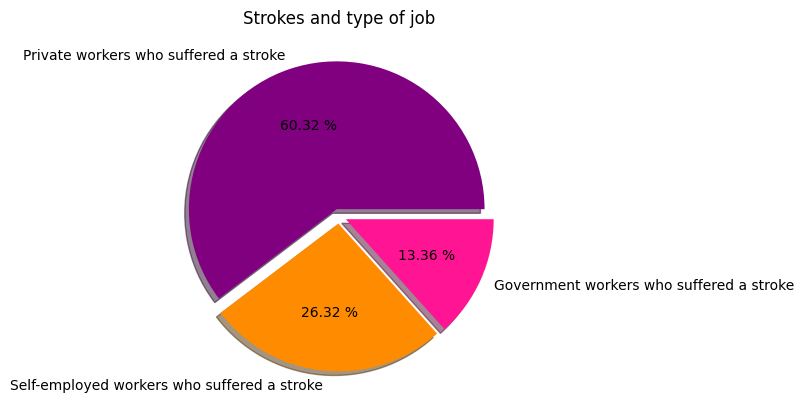

In [29]:
private_work_and_stroke = ((df.loc[df["work_type"]== "Private"])["stroke"] == 1).sum()
self_employed_and_stroke = ((df.loc[df["work_type"]== "Self-employed"])["stroke"] == 1).sum()
govt_work_and_stroke = ((df.loc[df["work_type"]== "Govt_job"])["stroke"] == 1).sum()

data = [private_work_and_stroke, self_employed_and_stroke, govt_work_and_stroke]
labels = ["Private workers who suffered a stroke", "Self-employed workers who suffered a stroke", "Government workers who suffered a stroke"]
explode=[.05, .05, .05,]
colors = ["purple", "darkorange", "deeppink"]

plt.title("Strokes and type of job")
plt.pie(data, labels=labels, colors=colors, autopct='%.2f %%', explode=explode, shadow=True)
plt.show()

In [30]:
private = df[df["work_type"] == "Private"].shape[0]
govt =  df[df["work_type"] == "Govt_job"].shape[0]
self_employed =  df[df["work_type"] == "Self-employed"].shape[0]

print(f"There are "+str(private)+" private workers in the dataset")
print(f"There are "+str(govt)+" government workers in the dataset")
print(f"There are "+str(self_employed)+" self-employed workers in the dataset")

There are 2925 private workers in the dataset
There are 657 government workers in the dataset
There are 819 self-employed workers in the dataset


Since there are significantly more private workers in the dataset, the pie chart is misleading in terms of relation between work type and stroke.

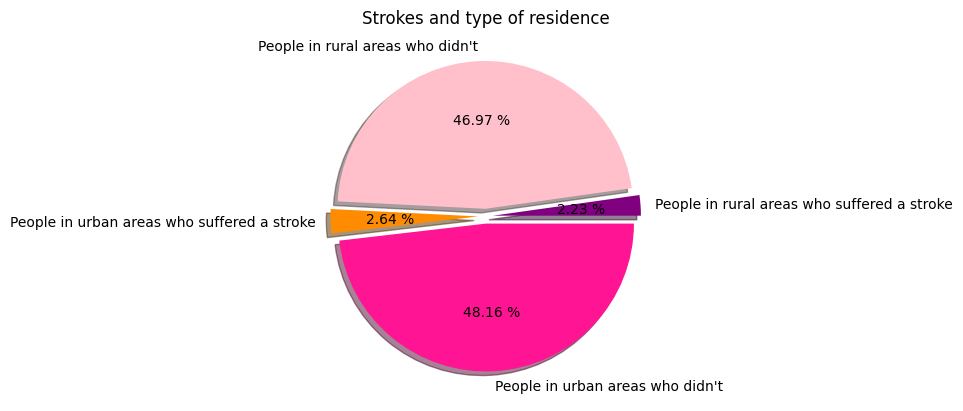

In [31]:
rural_and_stroke = ((df.loc[df["Residence_type"]== "Rural"])["stroke"] == 1).sum()
rural_and_no_stroke = ((df.loc[df["Residence_type"]== "Rural"])["stroke"] == 0).sum()
urban_and_stroke = ((df.loc[df["Residence_type"]== "Urban"])["stroke"] == 1).sum()
urban_and_no_stroke = ((df.loc[df["Residence_type"]== "Urban"])["stroke"] == 0).sum()

data = [rural_and_stroke, rural_and_no_stroke, urban_and_stroke, urban_and_no_stroke]
labels = ["People in rural areas who suffered a stroke", "People in rural areas who didn't", "People in urban areas who suffered a stroke", "People in urban areas who didn't"]
explode=[.05, .05, .05, .05]
colors = ["purple", "pink", "darkorange", "deeppink"]

plt.title("Strokes and type of residence")
plt.pie(data, labels=labels, colors=colors, autopct='%.2f %%', explode=explode, shadow=True)
plt.show()

There seems to be a slightly higher incidence of stroke among people who live in urban areas, but in order to verify this we need to see whether there are simply more people who live in urban areas in our dataset.

In [32]:
urban = df[df["Residence_type"] == "Urban"].shape[0]
rural =  df[df["Residence_type"] == "Rural"].shape[0]

print(f"There are "+str(urban)+" individuals living in urban areas in the dataset")
print(f"There are "+str(rural)+" individuals living in rural areas in the dataset")

There are 2596 individuals living in urban areas in the dataset
There are 2514 individuals living in rural areas in the dataset


The amount of individuals living in urban areas is slightly higher, therefore the higher incidence of strokes in urban areas seems irrelevant.

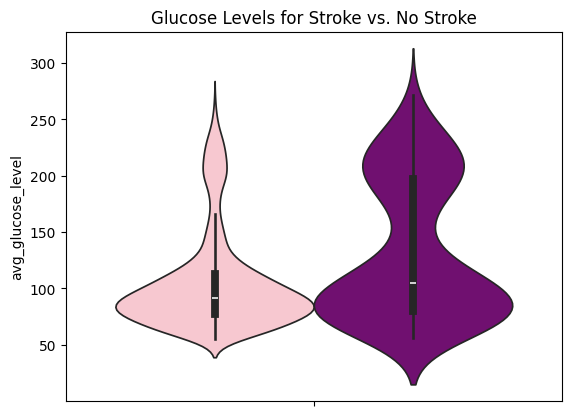

In [33]:
sns.violinplot(hue="stroke", y="avg_glucose_level", data=df, palette=["pink", "purple"], legend=False)
plt.title("Glucose Levels for Stroke vs. No Stroke")
plt.show()

In [34]:
fig = px.histogram(data_frame=df, x="avg_glucose_level", color= "stroke", color_discrete_sequence=["#b100cd", "#ff7600"])
fig.show()

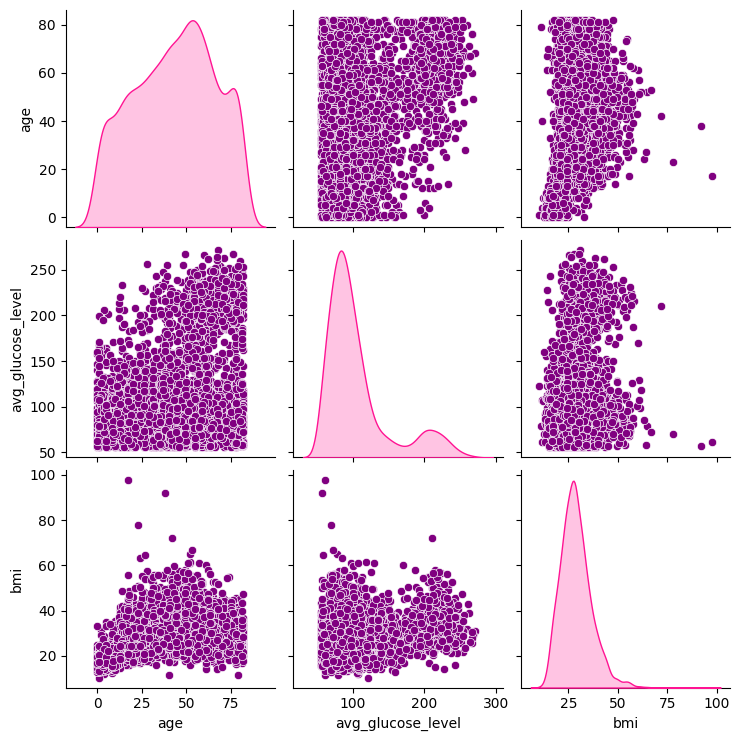

In [35]:
sns.pairplot(df[["age", "avg_glucose_level", "bmi"]], diag_kind="kde",
             plot_kws={"color": "purple"}, diag_kws={"color": "deeppink"})
plt.show()

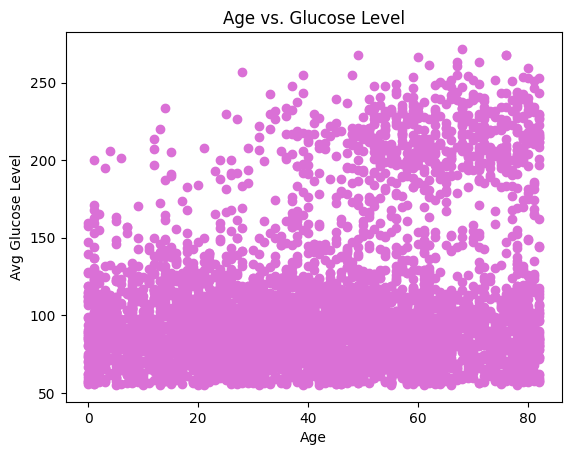

In [36]:
plt.scatter(df["age"], df["avg_glucose_level"], color="orchid")
plt.title("Age vs. Glucose Level")
plt.xlabel("Age")
plt.ylabel("Avg Glucose Level")
plt.show()

Overall, it seems that the factors that most affect stroke likelihood within our dataset are: age, hypertension and heart disease. In particular, age plays a key role.

## DATA PREPROCESSING

As previously stated, the "ID" column does not provide any useful information for predicting the risk of stroke, therefore we can safely drop it. Once that's done, we move on to dealing with the missing values, which present an issue for our model.

In [37]:
df.drop(columns=["id"], inplace=True)

In [38]:
df["bmi"].fillna(df["bmi"].median(), inplace=True)  # we fill in the missing BMI values with the median, since it is less sensitive to outliers

/tmp/ipykernel_2957/2614977317.py:1: FutureWarning:

A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.





In [39]:
df["smoking_status"].fillna(df["smoking_status"].mode()[0], inplace=True)  # we fill in the missing smoking_status values with the mode since it is the most frequent value in a categorical feature

/tmp/ipykernel_2957/2959060176.py:1: FutureWarning:

A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.





In [40]:
df.dropna(subset=["gender"], inplace=True)  # since there is only one "other" in gender, we drop that row

In [41]:
df["work_type"].fillna(df["work_type"].mode()[0], inplace=True)

/tmp/ipykernel_2957/3055214681.py:1: FutureWarning:

A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.





In [42]:
df.isnull().sum()  # we check for null values again

,0
gender,0
age,0
hypertension,0
heart_disease,0
ever_married,0
work_type,0
Residence_type,0
avg_glucose_level,0
bmi,0
smoking_status,0


Now we are ready to encode categorical features and scale the numerical ones so that the dataset may be suitable for modeling. For the numerical features, StandardScaler was employed, which standardizes the data by subtracting the mean and scaling to unit variance. This ensures that all numerical features are on the same scale, which is crucial for many machine learning algorithms that are sensitive to feature magnitudes. The categorical features were transformed using OneHotEncoder, which converts categorical variables into binary (0 or 1) columns. This is necessary because most machine learning models cannot work directly with categorical data. In order to apply this transformation simultaneously across the dataset, ColumnTransformer was used.

In [43]:
transformation = ColumnTransformer(
    transformers=[
        ("scale", StandardScaler(), ["age", "avg_glucose_level", "bmi"]),
        ("encode", OneHotEncoder(drop="first", categories="auto"),
         ["smoking_status", "work_type", "Residence_type", "gender", "ever_married"])
    ],
    remainder="drop",
    verbose_feature_names_out=False,
    sparse_threshold=0
)

In [44]:
transformation.fit(df)
X_transformed = pd.DataFrame(transformation.transform(df), columns=transformation.get_feature_names_out())
X_transformed.head()

,age,avg_glucose_level,bmi,smoking_status_never smoked,smoking_status_smokes,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Urban,gender_Male,ever_married_Yes
0,1.050758,2.706450,1.004893,0.0,0.0,1.0,0.0,0.0,1.0,1.0,1.0
1,0.785653,2.121652,-0.099142,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
2,1.625151,-0.004867,0.472358,1.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0
3,0.255444,1.437473,0.719142,0.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0
4,1.580967,1.501297,-0.631677,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0


In [45]:
X_transformed.shape[0]

5109

# TRAINING AND TEST SET

Now we split the dataset into features (X), which contains all the columns except the stroke column, i.e., what the model is trying to predict, and target variable (y), the stroke column.

In [46]:
X = X_transformed
y = df["stroke"]

In [47]:
X_train, X_test, y_train, y_test = train_test_split(X_transformed, y, test_size=0.2, stratify = y, random_state=42, shuffle=True)

In [48]:
X_test.head()

,age,avg_glucose_level,bmi,smoking_status_never smoked,smoking_status_smokes,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Urban,gender_Male,ever_married_Yes
3666,-0.672421,-0.496469,0.978915,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2217,-1.777024,-0.283574,-1.216166,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0
374,0.432181,-0.921817,0.277528,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
2392,-0.363133,-0.815370,1.810189,1.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0
299,0.653101,-0.261490,0.030744,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0


## IMBALANCE

First, we apply SMOTE in order to deal with the imbalance in the set, with only 4.9% having suffered a stroke. SMOTE is a powerful technique for handling imbalanced datasets by creating synthetic examples of the minority class. By generating synthetic data, SMOTE helps balance the class distribution and improves the model’s ability to learn from both the majority and minority classes, leading to better predictions for underrepresented outcomes.

In [49]:
smote = SMOTE(random_state=42)
X_train, y_train = smote.fit_resample(X_train, y_train)

# MODEL SELECTION

At this point we are going to implement various algorithms and then compare to see which one works best with our dataset.
We are going to use Logistic Regression, Random Forest Classifier, SVC, MLPClassifier and XGBClassifier.

# Logistic Regression

The first model we're going to apply is Logistic Regression, which is a statistical method predomintately used in binary classification tasks. It estimates the probability of something belonging to a certain class by using the logistic function (which turns all values inputed into a value between o and 1).

In [50]:
lr_model = LogisticRegression(class_weight="balanced", random_state=42)  # we initialize the Logistic Regression model
lr_model.fit(X_train, y_train)  # we fit the model to the training sets

LogisticRegression(class_weight='balanced', random_state=42)

Then we create a dictionary of hyperparameters that we will use later during grid search. These are parameters that are inherent to the model.

In [51]:
param_grid_lr = {
    "C": [0.01, 0.1, 1, 10],
    "penalty": ["l1", "l2"],
    "solver": ["liblinear"]
}

We create a K-Fold where the data is split into 5 folds, which are proportionate in regards to one another.

In [52]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

At this point we search for the best hyperparameters to use. Cross-validation is used to determine which parameters are the "best" for our model.

In [53]:
grid_search_lr = GridSearchCV(estimator=lr_model, param_grid=param_grid_lr, scoring="roc_auc", cv=skf)
grid_search_lr.fit(X_train, y_train)
best_model_lr = grid_search_lr.best_estimator_  # this gives us the best model that was found during the search

In [54]:
print("Best Parameters:", grid_search_lr.best_params_)

Best Parameters: {'C': 0.1, 'penalty': 'l2', 'solver': 'liblinear'}


Then we find the ROC AUC and accuracy scores of the best model we obtained during grid search.

In [55]:
cv_scores_lr = cross_val_score(best_model_lr, X_train, y_train, cv=skf, scoring='roc_auc')
print("Logistic Regression Cross-Validation ROC AUC Scores:", cv_scores_lr)
print("Mean ROC AUC:", cv_scores_lr.mean())

Logistic Regression Cross-Validation ROC AUC Scores: [0.83780341 0.85295928 0.85389061 0.84365085 0.85444148]
Mean ROC AUC: 0.8485491257145554


In [56]:
cv_score_lr_ac = cross_val_score(best_model_lr, X_train, y_train, cv=skf, scoring="accuracy")
print("Logistic Regression Cross-Validation Accuracy Scores:", cv_score_lr_ac)
print("Mean Accuracy:", cv_score_lr_ac.mean())

Logistic Regression Cross-Validation Accuracy Scores: [0.77827763 0.79549839 0.78778135 0.7755627  0.78135048]
Mean Accuracy: 0.7836941122012911


In [57]:
y_pred_lr = best_model_lr.predict(X_test)

Logistic Regression:
              precision    recall  f1-score   support

           0       0.98      0.73      0.84       972
           1       0.13      0.78      0.22        50

    accuracy                           0.73      1022
   macro avg       0.56      0.75      0.53      1022
weighted avg       0.94      0.73      0.81      1022

ROC AUC Score: 0.7541975308641975
Accuracy Score: 0.7309197651663405


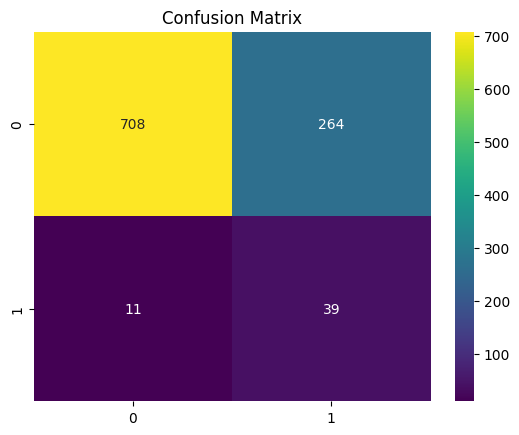

In [58]:
print("Logistic Regression:")
print(classification_report(y_test, y_pred_lr))
print(f"ROC AUC Score: {roc_auc_score(y_test, y_pred_lr)}")
print(f"Accuracy Score: {accuracy_score(y_test, y_pred_lr)}")

conf_matrix = confusion_matrix(y_test, y_pred_lr)
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="viridis")
plt.title("Confusion Matrix")
plt.show()

Overall, we can see the model performed well enough with identifying positive cases, however the rate of false negatives (type II error) is very high. Indeed, we can see that the recall of the model is around 73%.

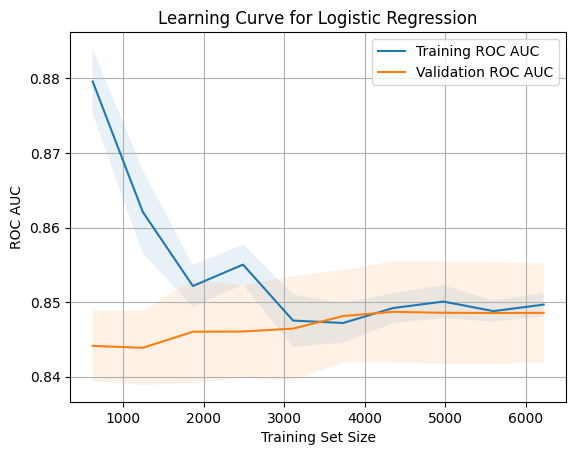

In [59]:
train_sizes, train_scores, test_scores = learning_curve(
    best_model_lr, X_train, y_train, cv=skf, scoring="roc_auc", train_sizes=np.linspace(0.1, 1.0, 10)
)

train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)
test_std = np.std(test_scores, axis=1)

plt.plot(train_sizes, train_mean, label="Training ROC AUC")
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.1)
plt.plot(train_sizes, test_mean, label="Validation ROC AUC")
plt.fill_between(train_sizes, test_mean - test_std, test_mean + test_std, alpha=0.1)
plt.xlabel("Training Set Size")
plt.ylabel("ROC AUC")
plt.title("Learning Curve for Logistic Regression")
plt.legend(loc="best")
plt.grid(True)
plt.show()

There is some overfitting in smaller set sizes, however the gap between the training score and the validation score decreases with larger set sizes, therefore the overfitting isn't severe. The validation score remains relatively stable throughout, indicating that the model is pretty consistent across training sizes and is able to discriminate between classes well enough. It can be observed that the training score drops towards the beginning, this means that as the model gets exposed to more diverse data, fitting the training data becomes more complex.

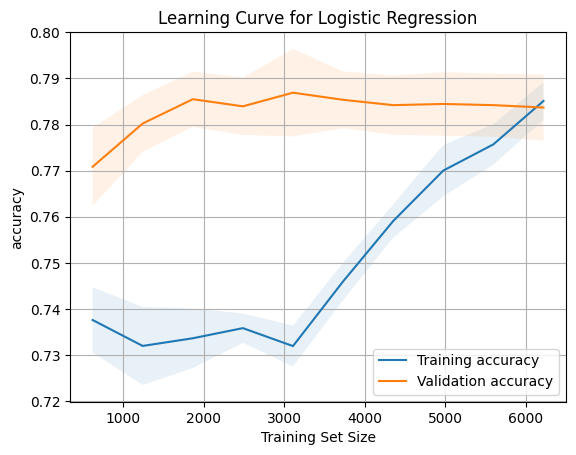

In [60]:
train_sizes, train_scores, test_scores = learning_curve(
    best_model_lr, X_train, y_train, cv=skf, scoring="accuracy", train_sizes=np.linspace(0.1, 1.0, 10)
)

train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)
test_std = np.std(test_scores, axis=1)

plt.plot(train_sizes, train_mean, label="Training accuracy")
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.1)
plt.plot(train_sizes, test_mean, label="Validation accuracy")
plt.fill_between(train_sizes, test_mean - test_std, test_mean + test_std, alpha=0.1)
plt.xlabel("Training Set Size")
plt.ylabel("accuracy")
plt.title("Learning Curve for Logistic Regression")
plt.legend(loc="best")
plt.grid(True)
plt.show()

Seeing as the training accuracy approaches the validation accuracy, we can say that the model is not overfitting, however there is some underfitting in the beginning stages, therefore the model struggles to be accurate with small training sets, but the more data is provided, the better the model performs in terms of accuracy.

Overall, it seems that the model's performance improves the more data it's given and it shows no clear signs of overfitting. However, its performance is subpar on small training sets.

# Random Forest Classifier

Next we're going to use Random Forest Classifier, an ensemble method (which combine multiple methods in order to obtain better results). This type of model reduces overfitting, improves accuracy and works well with large datasets.

In [61]:
rf_model = RandomForestClassifier(class_weight="balanced", random_state=42)
rf_model.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', random_state=42)

In [62]:
param_grid_rf = {
    "n_estimators": [100, 200, 500],
    "max_depth": [5, 10, 15]
}

In [63]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [64]:
grid_search_rf = GridSearchCV(estimator=rf_model, param_grid=param_grid_rf, scoring="roc_auc", cv=skf)
grid_search_rf.fit(X_train, y_train)
best_model_rf = grid_search_rf.best_estimator_

In [65]:
print("Best Parameters:", grid_search_rf.best_params_)

Best Parameters: {'max_depth': 15, 'n_estimators': 500}


In [66]:
cv_scores_rf = cross_val_score(best_model_rf, X_train, y_train, cv=skf, scoring='roc_auc')
print("Random Forest Cross-Validation ROC AUC Scores:", cv_scores_rf)
print("Mean ROC AUC:", cv_scores_rf.mean())

Random Forest Cross-Validation ROC AUC Scores: [0.98910759 0.9893078  0.99085534 0.99326061 0.9927693 ]
Mean ROC AUC: 0.9910601298558026


In [67]:
cv_score_rf_ac = cross_val_score(best_model_rf, X_train, y_train, cv=skf, scoring="accuracy")
print("Random Forest Cross-Validation Accuracy Scores:", cv_score_rf_ac)
print("Mean Accuracy:", cv_score_rf_ac.mean())

Random Forest Cross-Validation Accuracy Scores: [0.93701799 0.94340836 0.94662379 0.95691318 0.94919614]
Mean Accuracy: 0.946631894791658


In [68]:
y_pred_rf = best_model_rf.predict(X_test)

Random Forest:
              precision    recall  f1-score   support

           0       0.96      0.93      0.94       972
           1       0.17      0.30      0.22        50

    accuracy                           0.90      1022
   macro avg       0.57      0.61      0.58      1022
weighted avg       0.92      0.90      0.91      1022

ROC AUC Score: 0.6129629629629629
Accuracy Score: 0.8953033268101761


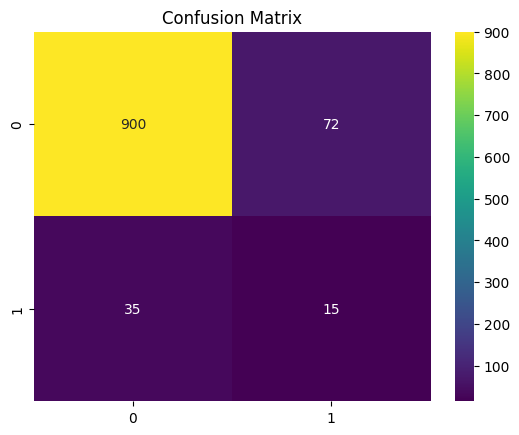

In [69]:
print("Random Forest:")
print(classification_report(y_test, y_pred_rf))
print(f"ROC AUC Score: {roc_auc_score(y_test, y_pred_rf)}")
print(f"Accuracy Score: {accuracy_score(y_test, y_pred_rf)}")

conf_matrix = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="viridis")
plt.title("Confusion Matrix")
plt.show()

Clearly, this model exhibits a very good ability to predict positive cases, indeed it has high precision and recall scores, but there seems to be some issue with the negative class, indeed we see 35 false positives, indicating it may be biased towards the positive class.

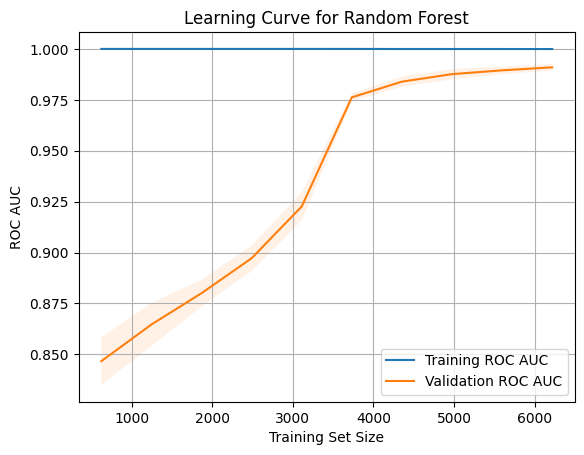

In [70]:
train_sizes, train_scores, test_scores = learning_curve(
    best_model_rf, X_train, y_train, cv=skf, scoring="roc_auc", train_sizes=np.linspace(0.1, 1.0, 10)
)

train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)
test_std = np.std(test_scores, axis=1)

plt.plot(train_sizes, train_mean, label="Training ROC AUC")
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.1)
plt.plot(train_sizes, test_mean, label="Validation ROC AUC")
plt.fill_between(train_sizes, test_mean - test_std, test_mean + test_std, alpha=0.1)
plt.xlabel("Training Set Size")
plt.ylabel("ROC AUC")
plt.title("Learning Curve for Random Forest")
plt.legend(loc="best")
plt.grid(True)
plt.show()

The training score remains consistent at 1, this is a perfect performance and it indicates that the model fits the training set extremely well. The validation starts pretty low, but it increases as the training set size increases, ultimately stabilizing, indicating that the model gets pretty good at generalizing and develops a pretty good ability to distinguish between classes.
However, it must be noted that the perfect performance of the training score is most likely a sign that the model is memorizing the training data rather than actually learning patterns, especially since the validation performance is lower. This is indicative of overfitting.

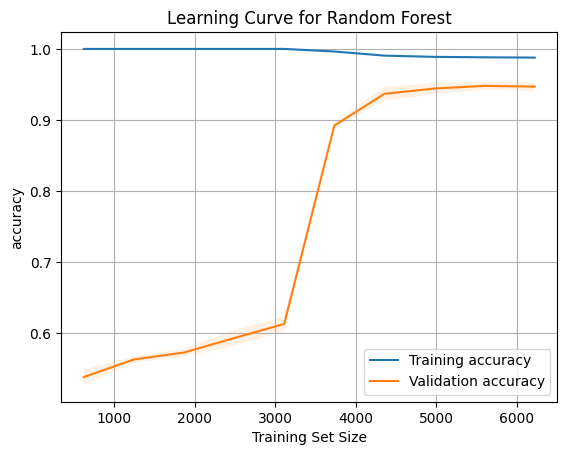

In [71]:
train_sizes, train_scores, test_scores = learning_curve(
    best_model_rf, X_train, y_train, cv=skf, scoring="accuracy", train_sizes=np.linspace(0.1, 1.0, 10)
)

train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)
test_std = np.std(test_scores, axis=1)

plt.plot(train_sizes, train_mean, label="Training accuracy")
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.1)
plt.plot(train_sizes, test_mean, label="Validation accuracy")
plt.fill_between(train_sizes, test_mean - test_std, test_mean + test_std, alpha=0.1)
plt.xlabel("Training Set Size")
plt.ylabel("accuracy")
plt.title("Learning Curve for Random Forest")
plt.legend(loc="best")
plt.grid(True)
plt.show()

The training accuracy score, while not exactly perfect, also remains pretty consistent at around 1, therefore the model is fitting the data almost perfectly. On the other hand, the validation accuracy starts off pretty low, but gets better as the training set size increases (at around 3000 there is a surge upwards) and then stabilizes, this means that the model's ability to generalize gets better as the training set size gets bigger.
Once more, all this seems to indicate that the model is memorizing the training data rather than learning how to generalize from it. Once more, this is a sign of overfitting.

Overall, the model seems to perform pretty well once a certain amount (between 3000 and 4000) of training samples is used.

# SVC

Next, we are going to implement a Support Vector Classifier model (SVC). It's a type of SVMs, which are powerful and flexible algorithms that work pretty well for classification tasks. It works by finding the optimal decision boundary that separates different classes in the feature space.

In [72]:
svc_model = SVC(class_weight="balanced", random_state=42)
svc_model.fit(X_train, y_train)
svc_pred = svc_model.predict(X_test)

In [73]:
param_grid_svc = {
    "C": [0.1, 1, 10],
    "kernel": ["linear", "rbf", "poly"],
    "gamma": ["scale", "auto"]
}

In [74]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [75]:
grid_search_svc = GridSearchCV(estimator=svc_model, param_grid=param_grid_svc, scoring="roc_auc", cv=skf)
grid_search_svc.fit(X_train, y_train)
best_model_svc = grid_search_svc.best_estimator_

In [76]:
print("Best Parameters:", grid_search_svc.best_params_)

Best Parameters: {'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}


In [77]:
cv_scores_svc = cross_val_score(best_model_svc, X_train, y_train, cv=skf, scoring='roc_auc')
print("SVC Cross-Validation ROC AUC Scores:", cv_scores_svc)
print("Mean ROC AUC:", cv_scores_svc.mean())

SVC Cross-Validation ROC AUC Scores: [0.95685166 0.96099625 0.9615223  0.9653221  0.96171254]
Mean ROC AUC: 0.961280969720314


In [78]:
cv_score_svc_ac = cross_val_score(best_model_svc, X_train, y_train, cv=skf, scoring="accuracy")
print("Random Forest Cross-Validation Accuracy Scores:", cv_score_svc_ac)
print("Mean Accuracy:", cv_score_svc_ac.mean())

Random Forest Cross-Validation Accuracy Scores: [0.90102828 0.9073955  0.9170418  0.91446945 0.90160772]
Mean Accuracy: 0.9083085494176675


In [79]:
y_pred_svc = best_model_svc.predict(X_test)

SVC:
              precision    recall  f1-score   support

           0       0.97      0.85      0.90       972
           1       0.15      0.52      0.23        50

    accuracy                           0.83      1022
   macro avg       0.56      0.68      0.57      1022
weighted avg       0.93      0.83      0.87      1022

ROC AUC Score: 0.6833539094650206
Accuracy Score: 0.8307240704500979


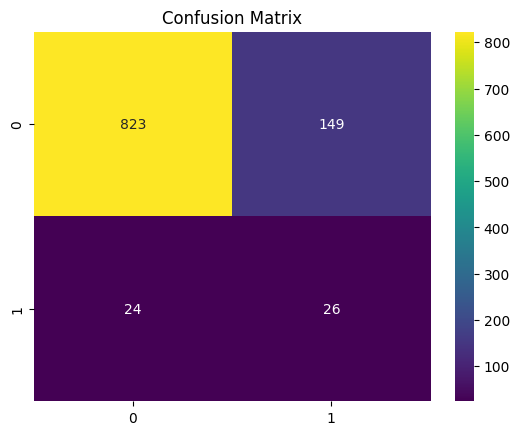

In [80]:
print("SVC:")
print(classification_report(y_test, y_pred_svc))
print(f"ROC AUC Score: {roc_auc_score(y_test, y_pred_svc)}")
print(f"Accuracy Score: {accuracy_score(y_test, y_pred_svc)}")

conf_matrix = confusion_matrix(y_test, y_pred_svc)
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="viridis")
plt.title("Confusion Matrix")
plt.show()

The models performs well enough at identifying and predicting positive cases, indeed it has high precision and moderate recall, but it struggles at identifying and predicting negative cases, indicating it does not discriminate very well between the two classes.

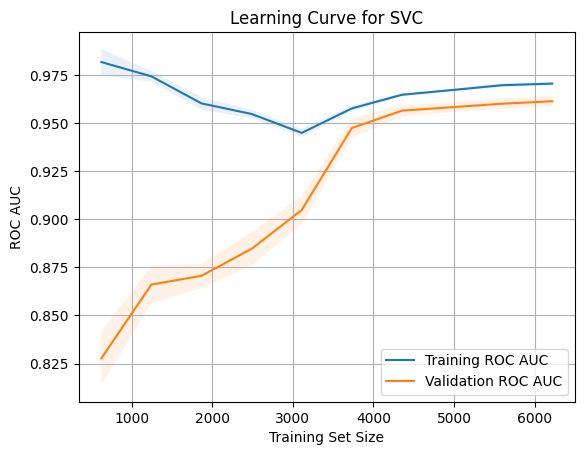

In [81]:
train_sizes, train_scores, test_scores = learning_curve(
    best_model_svc, X_train, y_train, cv=skf, scoring="roc_auc", train_sizes=np.linspace(0.1, 1.0, 10)
)

train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)
test_std = np.std(test_scores, axis=1)

plt.plot(train_sizes, train_mean, label="Training ROC AUC")
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.1)
plt.plot(train_sizes, test_mean, label="Validation ROC AUC")
plt.fill_between(train_sizes, test_mean - test_std, test_mean + test_std, alpha=0.1)
plt.xlabel("Training Set Size")
plt.ylabel("ROC AUC")
plt.title("Learning Curve for SVC")
plt.legend(loc="best")
plt.grid(True)
plt.show()

The training score starts very high and never falls below 0.925, indicating the model works pretty well at fitting the data, even with a small training set. The slight drop can be explained by the model encountering more varied data. The validation score starts pretty low, meaning the model has trouble generalizing when it's not exposed to enough data, but eventually it increases and stabilizes at around training set size 4000.
There is no severe overfitting, indeed the two scores get significantly closer to one another as the training set size increases. The fact that both the training and the validation scores stabilize at around 0.96 indicates that the model performs pretty well at distinguishng between classes.

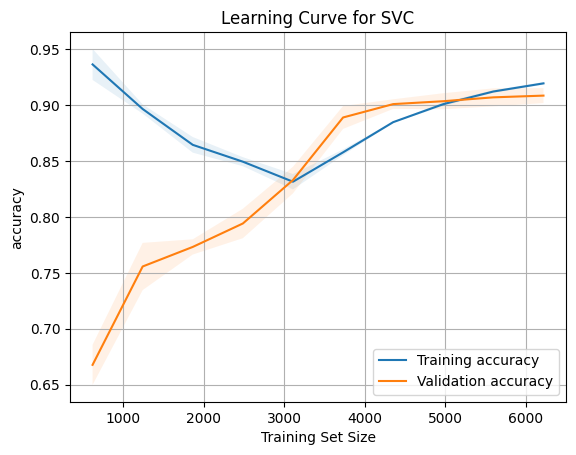

In [82]:
train_sizes, train_scores, test_scores = learning_curve(
    best_model_svc, X_train, y_train, cv=skf, scoring="accuracy", train_sizes=np.linspace(0.1, 1.0, 10)
)

train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)
test_std = np.std(test_scores, axis=1)

plt.plot(train_sizes, train_mean, label="Training accuracy")
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.1)
plt.plot(train_sizes, test_mean, label="Validation accuracy")
plt.fill_between(train_sizes, test_mean - test_std, test_mean + test_std, alpha=0.1)
plt.xlabel("Training Set Size")
plt.ylabel("accuracy")
plt.title("Learning Curve for SVC")
plt.legend(loc="best")
plt.grid(True)
plt.show()

The training score, as in the earlier graph, starts pretty high and then drops, which is not unexpected behavior, it simply means that as the model is exposed to more data, it becomes less likely to overfit. Eventually the score picks up again and stabilizes at around training set size 5000. The validation score starts pretty low, but consistently picks up as the model is exposed to more data, eventually stabilizing when the training set size reaches 4000 (more or less).
Therefore we can say that overfitting is not a significant issue, since the model seems to learn how to generalize when the training set size increases, which is also showcased by the fact that the gap between validation and training diminishes.

Overall, the model performs very well at generalizing once a certain training set size is reached and the model does not seem to be overfitting. It does show some underfitting for lower data sets, but this issue is overcome and the gap narrows. All in all, the model appears to perform pretty well.

# MLP

Then we use Multulayer Perceptron, a type of artificial neural network in the family of feedforward neural networks, commonly used for classification tasks. It is made of multiple layers of neurons (perceptrons) arranged in input layers, hidden layers and output layers.

In [83]:
mlp_model = MLPClassifier(random_state=42, max_iter=500, learning_rate_init=0.01)
mlp_model.fit(X_train, y_train)
mlp_pred = mlp_model.predict(X_test)

Since neural netwrok models typically take longer, we are going to do a randomized search rather than a grid search.

In [84]:
param_dist_mlp = {
    "hidden_layer_sizes": [(50,), (100,), (50, 50)],
    "activation": ["tanh", "relu"],
    "solver": ["adam", "sgd"],
    "alpha": uniform(loc=0.0001, scale=0.05),
    "learning_rate": ["constant", "adaptive"],
    "max_iter": [200],
}

In [85]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [86]:
random_search_mlp = RandomizedSearchCV(estimator=mlp_model, param_distributions=param_dist_mlp, scoring="roc_auc", cv=skf)
random_search_mlp.fit(X_train, y_train)
best_model_mlp = random_search_mlp.best_estimator_

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning:

Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning:

Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning:

Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning:

Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning:

Stochastic Optimizer: Maximum

In [87]:
print("Best Parameters:", random_search_mlp.best_params_)

Best Parameters: {'activation': 'tanh', 'alpha': np.float64(0.024851259526931384), 'hidden_layer_sizes': (50, 50), 'learning_rate': 'constant', 'max_iter': 200, 'solver': 'adam'}


In [88]:
cv_scores_mlp = cross_val_score(best_model_mlp, X_train, y_train, cv=skf, scoring='roc_auc')
print("MLPClassifier Cross-Validation ROC AUC Scores:", cv_scores_mlp)
print("Mean ROC AUC:", cv_scores_mlp.mean())

MLPClassifier Cross-Validation ROC AUC Scores: [0.96913845 0.97671156 0.96805822 0.9709763  0.97254783]
Mean ROC AUC: 0.9714864733460964


In [89]:
cv_score_mlp_ac = cross_val_score(best_model_mlp, X_train, y_train, cv=skf, scoring="accuracy")
print("Random Forest Cross-Validation Accuracy Scores:", cv_score_mlp_ac)
print("Mean Accuracy:", cv_score_mlp_ac.mean())

Random Forest Cross-Validation Accuracy Scores: [0.93187661 0.94276527 0.93890675 0.94212219 0.94019293]
Mean Accuracy: 0.939172748989494


In [90]:
y_pred_mlp = best_model_mlp.predict(X_test)

MLPClassifier:
              precision    recall  f1-score   support

           0       0.96      0.92      0.94       972
           1       0.17      0.30      0.22        50

    accuracy                           0.89      1022
   macro avg       0.57      0.61      0.58      1022
weighted avg       0.92      0.89      0.91      1022

ROC AUC Score: 0.6119341563786008
Accuracy Score: 0.8933463796477495


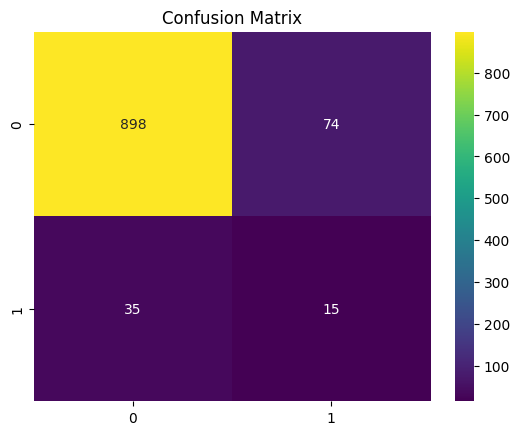

In [91]:
print("MLPClassifier:")
print(classification_report(y_test, y_pred_mlp))
print(f"ROC AUC Score: {roc_auc_score(y_test, y_pred_mlp)}")
print(f"Accuracy Score: {accuracy_score(y_test, y_pred_mlp)}")

conf_matrix = confusion_matrix(y_test, y_pred_mlp)
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="viridis")
plt.title("Confusion Matrix")
plt.show()

The model performs pretty well on the positive class, indeed it has high precision and recall, with an f1 score of 0.93. However, it shows issues with the negative class.

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning:

Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning:

Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning:

Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning:

Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning:

Stochastic Optimizer: Maximum

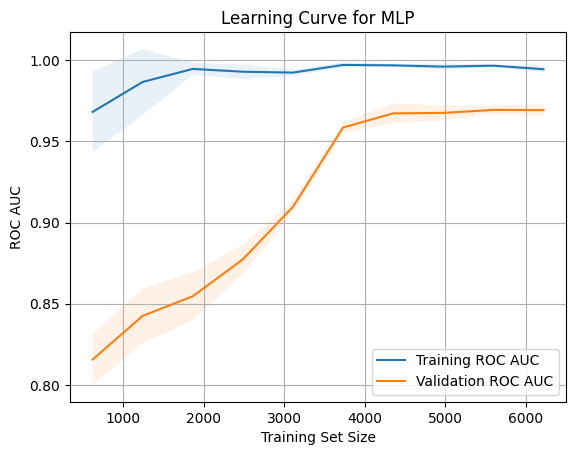

In [92]:
train_sizes, train_scores, test_scores = learning_curve(
    best_model_mlp, X_train, y_train, cv=skf, scoring="roc_auc", train_sizes=np.linspace(0.1, 1.0, 10)
)

train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)
test_std = np.std(test_scores, axis=1)

plt.plot(train_sizes, train_mean, label="Training ROC AUC")
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.1)
plt.plot(train_sizes, test_mean, label="Validation ROC AUC")
plt.fill_between(train_sizes, test_mean - test_std, test_mean + test_std, alpha=0.1)
plt.xlabel("Training Set Size")
plt.ylabel("ROC AUC")
plt.title("Learning Curve for MLP")
plt.legend(loc="best")
plt.grid(True)
plt.show()

The training score remains pretty consisten at around 1, indicating that the model fits the data pretty well, meaning the model has a pretty good ability to discriminate between classes. The validation score starts lower but increases consistently, stabilizing when the training sets reaches a size of about 4000.
Therefore we can say the model generalizes pretty well once the training set reaches a certain size and the model does not show any significant signs of overfitting. Clearly, the model benefits from having more data.

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning:

Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning:

Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning:

Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning:

Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning:

Stochastic Optimizer: Maximum

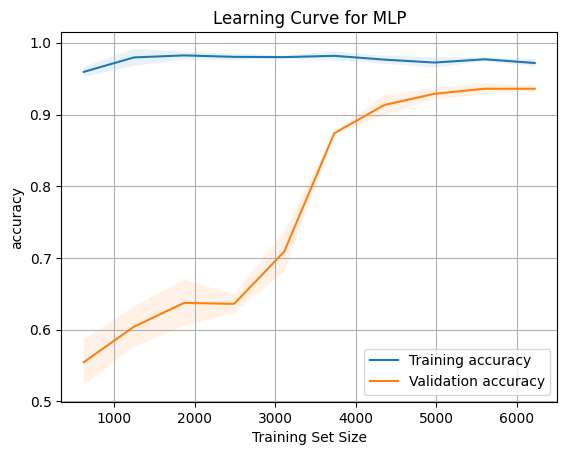

In [93]:
train_sizes, train_scores, test_scores = learning_curve(
    best_model_mlp, X_train, y_train, cv=skf, scoring="accuracy", train_sizes=np.linspace(0.1, 1.0, 10)
)

train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)
test_std = np.std(test_scores, axis=1)

plt.plot(train_sizes, train_mean, label="Training accuracy")
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.1)
plt.plot(train_sizes, test_mean, label="Validation accuracy")
plt.fill_between(train_sizes, test_mean - test_std, test_mean + test_std, alpha=0.1)
plt.xlabel("Training Set Size")
plt.ylabel("accuracy")
plt.title("Learning Curve for MLP")
plt.legend(loc="best")
plt.grid(True)
plt.show()

Once more, the training score consistently remains pretty high, meaning that the model fits the data almost perfectly, it drops slightly as the training set size increases. The validation score starts significantly lower, meaning that the model struggles to generalize when it is not given enough data, however the score increases as the model is exposed to more data, eventually stabilizing when the training set size is at about 4000.
The model shows signs of overfitting with small training sets, but the gap between the scores narrows with bigger sets. It also becomes pretty good at generalizing once it's fed enough data. After training set size reaches 5000, the performance seems to remain stable.

Overall, the model overfits with smaller training set sizes, but improves much when the training sets get bigger and the model learns how to generalize pretty well and performs well enough on unseen data.

# XGB

Last but not least, we use Extreme Gradient Boosting, which is based on the gradient boosting network. It is very efficient and accurate.

In [94]:
xgb_model = XGBClassifier(random_state=42)
xgb_model.fit(X_train, y_train)
xgb_pred = xgb_model.predict(X_test)

In [95]:
param_grid_xgb = {
    "n_estimators": [100, 200, 500],
    "learning_rate": [0.01, 0.1, 0.2],
    "max_depth": [3, 5, 7],
    "subsample": [0.8, 1],
    "colsample_bytree": [0.8, 1]
}

In [96]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [97]:
grid_search_xgb = GridSearchCV(estimator=xgb_model, param_grid=param_grid_xgb, scoring="roc_auc", cv=skf)
grid_search_xgb.fit(X_train, y_train)
best_model_xgb = grid_search_xgb.best_estimator_

In [98]:
print("Best Parameters:", grid_search_xgb.best_params_)

Best Parameters: {'colsample_bytree': 1, 'learning_rate': 0.1, 'max_depth': 7, 'n_estimators': 500, 'subsample': 1}


In [99]:
cv_scores_xgb = cross_val_score(best_model_xgb, X_train, y_train, cv=skf, scoring='roc_auc')
print("XGBoost Cross-Validation ROC AUC Scores:", cv_scores_xgb)
print("Mean ROC AUC:", cv_scores_xgb.mean())

XGBoost Cross-Validation ROC AUC Scores: [0.99251921 0.99222671 0.99337806 0.99275111 0.99441031]
Mean ROC AUC: 0.9930570813363024


In [100]:
cv_score_xgb_ac = cross_val_score(best_model_xgb, X_train, y_train, cv=skf, scoring="accuracy")
print("Random Forest Cross-Validation Accuracy Scores:", cv_score_xgb_ac)
print("Mean Accuracy:", cv_score_xgb_ac.mean())

Random Forest Cross-Validation Accuracy Scores: [0.95372751 0.95241158 0.95819936 0.97041801 0.95884244]
Mean Accuracy: 0.9587197778126783


In [101]:
y_pred_xgb = best_model_xgb.predict(X_test)

XGBoost:
              precision    recall  f1-score   support

           0       0.96      0.97      0.96       972
           1       0.26      0.22      0.24        50

    accuracy                           0.93      1022
   macro avg       0.61      0.59      0.60      1022
weighted avg       0.93      0.93      0.93      1022

ROC AUC Score: 0.5935390946502057
Accuracy Score: 0.9305283757338552


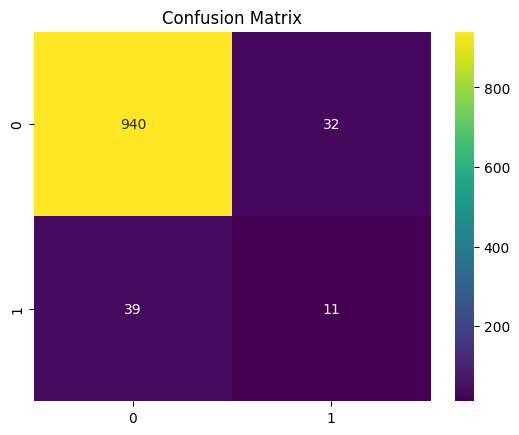

In [102]:
print("XGBoost:")
print(classification_report(y_test, y_pred_xgb))
print(f"ROC AUC Score: {roc_auc_score(y_test, y_pred_xgb)}")
print(f"Accuracy Score: {accuracy_score(y_test, y_pred_xgb)}")

conf_matrix = confusion_matrix(y_test, y_pred_xgb)
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="viridis")
plt.title("Confusion Matrix")
plt.show()

The model is very efficient at identifying and predicting positive cases (it has very high precision and recall), however it shows poor performance on the negative class.

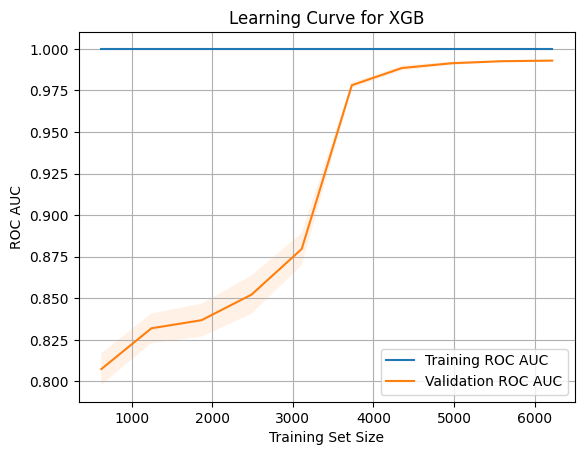

In [103]:
train_sizes, train_scores, test_scores = learning_curve(
    best_model_xgb, X_train, y_train, cv=skf, scoring="roc_auc", train_sizes=np.linspace(0.1, 1.0, 10)
)

train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)
test_std = np.std(test_scores, axis=1)

plt.plot(train_sizes, train_mean, label="Training ROC AUC")
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.1)
plt.plot(train_sizes, test_mean, label="Validation ROC AUC")
plt.fill_between(train_sizes, test_mean - test_std, test_mean + test_std, alpha=0.1)
plt.xlabel("Training Set Size")
plt.ylabel("ROC AUC")
plt.title("Learning Curve for XGB")
plt.legend(loc="best")
plt.grid(True)
plt.show()

The training score remains consistent at 1, indicating a perfect performance and that the model is fitting the data perfectly. This is a sign of overfitting, meaning that the model might not generalize very well. The validation score is low when the model is exposed to small amount of data, but increases significantly when the training set size reaches 4000 and then stabilizes. This indicates a strong generalization performance once the dataset gets bigger.

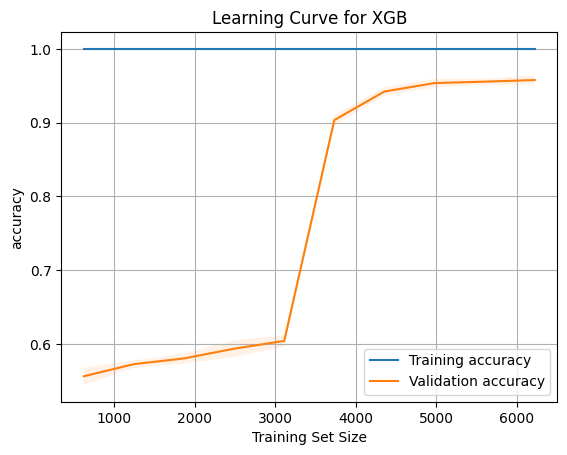

In [104]:
train_sizes, train_scores, test_scores = learning_curve(
    best_model_xgb, X_train, y_train, cv=skf, scoring="accuracy", train_sizes=np.linspace(0.1, 1.0, 10)
)

train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)
test_std = np.std(test_scores, axis=1)

plt.plot(train_sizes, train_mean, label="Training accuracy")
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.1)
plt.plot(train_sizes, test_mean, label="Validation accuracy")
plt.fill_between(train_sizes, test_mean - test_std, test_mean + test_std, alpha=0.1)
plt.xlabel("Training Set Size")
plt.ylabel("accuracy")
plt.title("Learning Curve for XGB")
plt.legend(loc="best")
plt.grid(True)
plt.show()

Once more, the training score stays pretty consistently at 1, indicating that the model fits the data perfectly and this is a sign of overfitting. The validation score starts significantly lower and starts increasing significantly after the training set size surpasses 3000, eventually stabilizing at around 4000 with a pretty high score.
All this indicates that the model struggles with overfitting when it's not fed sufficient data since it has issues generalizing, but shows a clear improvement once the training set size increases.

Overall, the model's performance gets better with larger training sets, instead showing signs of overfitting with smaller sizes. However, it eventually develops pretty good generalization abilities and the gap between the training score and validation score narrows.

# COMPARISON BETWEEN MODELS

Now it's time to compare the different models so that we can determine which one performs best.

In [105]:
# @title
def calculate_metrics(y_test, y_pred):
  cm = confusion_matrix(y_test, y_pred)
  tn, fp, fn, tp = cm.ravel()
  accuracy = accuracy_score(y_test, y_pred)
  f1 = f1_score(y_test, y_pred)
  precision = precision_score(y_test, y_pred)
  recall = recall_score(y_test, y_pred)
  specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
  roc_auc = roc_auc_score(y_test, y_pred)
  return tn, tp, fn, fp, accuracy, f1, precision, recall, specificity, roc_auc

models = [
    (best_model_lr, "Logistic Regression"),
    (best_model_rf, "Random Forest"),
    (best_model_svc, "SVC"),
    (best_model_mlp, "MLP"),
    (best_model_xgb, "XGBoost")
]

results = []
for model, model_name in models:
  y_pred = model.predict(X_test)
  tn, tp, fn, fp, accuracy, f1, precision, recall, specificity, roc_auc = calculate_metrics(y_test, y_pred)
  results.append([model_name, tn, tp, fn, fp, accuracy, f1, precision, recall, specificity, roc_auc])

df_results = pd.DataFrame(results, columns=["Model", "True Negatives", "True Positives", "False Negatives", "False Positives", "Accuracy", "F1 Score", "Precision", "Recall", "Specificity", "ROC AUC"])

print(df_results)

                 Model  True Negatives  True Positives  False Negatives  \
0  Logistic Regression             708              39               11   
1        Random Forest             900              15               35   
2                  SVC             823              26               24   
3                  MLP             898              15               35   
4              XGBoost             940              11               39   

   False Positives  Accuracy  F1 Score  Precision  Recall  Specificity  \
0              264  0.730920  0.220963   0.128713    0.78     0.728395   
1               72  0.895303  0.218978   0.172414    0.30     0.925926   
2              149  0.830724  0.231111   0.148571    0.52     0.846708   
3               74  0.893346  0.215827   0.168539    0.30     0.923868   
4               32  0.930528  0.236559   0.255814    0.22     0.967078   

    ROC AUC  
0  0.754198  
1  0.612963  
2  0.683354  
3  0.611934  
4  0.593539  


## RANKING

In [106]:
# @title
display(Markdown(f"""
XGB:

Best overall performance with **{accuracy_score(y_test, y_pred_xgb)}** accuracy. The learning curve shows that XGBoost is excellent at generalizing as the dataset grows, with high ROC AUC and accuracy. Potential downside: it may raise more false positives."""))


XGB:

Best overall performance with **0.9305283757338552** accuracy. The learning curve shows that XGBoost is excellent at generalizing as the dataset grows, with high ROC AUC and accuracy. Potential downside: it may raise more false positives.

In [107]:
# @title
display(Markdown(f"""
RANDOM FOREST:

Strong performance with **{accuracy_score(y_test, y_pred_rf)}** accuracy and a good balance between precision and recall. Overfitting is an issue, especially with smaller datasets, but validation performance improves with more data. It may not handle negative cases well."""))


RANDOM FOREST:

Strong performance with **0.8953033268101761** accuracy and a good balance between precision and recall. Overfitting is an issue, especially with smaller datasets, but validation performance improves with more data. It may not handle negative cases well.

In [108]:
# @title
display(Markdown(f"""
MLP:

Good performance with **{accuracy_score(y_test, y_pred_mlp)}** accuracy. MLP overfits with small datasets but generalizes well with more data. It may have trouble identifying true negatives."""))


MLP:

Good performance with **0.8933463796477495** accuracy. MLP overfits with small datasets but generalizes well with more data. It may have trouble identifying true negatives.

In [109]:
# @title
display(Markdown(f"""
SVC:

Moderate performance with **{accuracy_score(y_test, y_pred_svc)}** accuracy. Initially underfits but improves significantly with more data. Performance on negative cases is passable."""))


SVC:

Moderate performance with **0.8307240704500979** accuracy. Initially underfits but improves significantly with more data. Performance on negative cases is passable.

In [110]:
# @title
display(Markdown(f"""
LOGISTIC REGRESSION:

Weakest performance overall with **{accuracy_score(y_test, y_pred_lr)}** accuracy. The learning curves show signs of underfitting, indicating that the model struggles to capture complex relationships in the data."""))


LOGISTIC REGRESSION:

Weakest performance overall with **0.7309197651663405** accuracy. The learning curves show signs of underfitting, indicating that the model struggles to capture complex relationships in the data.

# CONCLUSIONS

Overall, all models seem to somewhat struggle with predicting negative cases. The model that showed the best general performance is XGB. MLP and Random Forest also performed pretty well. SVC performed moderately and had the highest specificity. Logistic Regression is the one that performed the worst, despite having the largest amount of True Negatives.